# Tutorial 3: Downloading data from USGS

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/gopalam/PyEGRET/blob/main/tutorials/03_usgs_data.ipynb)

For a USGS monitoring location, you do not need to prepare any files: the
discharge record, the water-quality results and the site information can be
downloaded directly. PyEGRET has three readers for this, each a translation
of the R EGRET function of the same purpose:

| PyEGRET | R EGRET | what it reads |
|---|---|---|
| `read_waterdata_daily` | `readNWISDaily` | daily mean discharge |
| `read_waterdata_sample` | `readNWISSample` | discrete water-quality results |
| `read_waterdata_info` | `readNWISInfo` | site and parameter information |

They use the USGS Water Data APIs (<https://api.waterdata.usgs.gov>), which
replace the older NWIS web services, through USGS's own Python package,
[dataretrieval](https://github.com/DOI-USGS/dataretrieval-python). This
notebook downloads the Choptank River record from Tutorial 1, looks carefully
at what comes back, and shows that it reproduces the record distributed with
EGRET. It needs an internet connection.

In [1]:
import os
import sys

# If this notebook sits in PyEGRET/tutorials, PyEGRET is one folder up and is
# used straight from there, with nothing installed. Anywhere else (Google
# Colab, say) it is installed from GitHub, and the data are read from GitHub.
HERE = os.path.abspath("")
ROOT = os.path.dirname(HERE)
if os.path.isdir(os.path.join(ROOT, "pyegret")):
    sys.path.insert(0, ROOT)
else:
    try:
        import pyegret
    except ImportError:
        import subprocess
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check",
                        "pyegret @ git+https://github.com/gopalam/PyEGRET"], check=True)

# The example data: the data folder next to this notebook, or else GitHub.
DATA = os.path.join(HERE, "data")
if not os.path.isdir(DATA):
    DATA = "https://raw.githubusercontent.com/gopalam/PyEGRET/main/tutorials/data"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyegret

print("PyEGRET", pyegret.__version__)

PyEGRET 0.1.0


The readers need `dataretrieval`. The next cell installs it if it is missing;
you can also install it yourself with `pip install dataretrieval`, or install
PyEGRET with its USGS extra, `pip install "pyegret[usgs] @ git+https://github.com/gopalam/PyEGRET"`.
`dataretrieval` may print a note that Geopandas is not installed, and a line
for each download; PyEGRET does not need Geopandas.

In [2]:
try:
    import dataretrieval
except ImportError:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check",
                    "dataretrieval"], check=True)
    import dataretrieval

print("dataretrieval", dataretrieval.__version__)

Geopandas not installed. Geometries will be flattened into pandas DataFrames.


dataretrieval 1.4.0


## 1. Finding the codes

Two codes identify what to download. The **site number** is the USGS
monitoring-location number, eight to fifteen digits, shown on the site's page
at Water Data for the Nation (for this site,
<https://waterdata.usgs.gov/monitoring-location/USGS-01491000/>). The
**parameter code** is a five-digit code for the measured quantity. A few that
WRTDS studies often use:

| code | parameter |
|---|---|
| 00060 | discharge, cubic feet per second (daily mean) |
| 00631 | nitrate plus nitrite, filtered, mg/L as N |
| 00600 | total nitrogen, mg/L |
| 00665 | phosphorus, unfiltered, mg/L as P |
| 00940 | chloride, filtered, mg/L |
| 80154 | suspended sediment concentration, mg/L |

The full list is at <https://help.waterdata.usgs.gov/codes-and-parameters/parameters>.
You can also look a code up from Python, through the same service the readers
use:

In [3]:
from dataretrieval import waterdata

codes, _ = waterdata.get_reference_table("parameter-codes", query={"id": "00631"})
codes[["parameter_code", "parameter_name", "unit_of_measure", "parameter_description"]]

Retrieving: parameter-codes · 1 page · 1 rows

,parameter_code,parameter_name,unit_of_measure,parameter_description
0,00631,"NO3+NO2, wf",mg/l as N,"Nitrate plus nitrite, water, filtered, milligr..."


In [4]:
SITE = "01491000"            # Choptank River near Greensboro, MD
PARAMETER = "00631"          # nitrate plus nitrite, mg/L as N
START = "1979-10-01"
END = "2011-09-30"

## 2. Site information

`read_waterdata_info` returns the site's record from the monitoring-locations
service, with the columns EGRET adds: `shortName` and `station_nm` (the site
name), `drainSqKm` (converted from the square miles USGS reports), the
parameter's name and units from the parameter-code table, and the water year
as the period of analysis. As in R, a parameter whose units are not mg/L
brings a warning, because flux would then be computed wrongly.

In [5]:
from pyegret.data.read_waterdata import (read_waterdata_daily, read_waterdata_info,
                                         read_waterdata_sample)

info = read_waterdata_info(SITE, PARAMETER)
info[["monitoring_location_id", "shortName", "drainage_area", "drainSqKm",
      "paramShortName", "param.units", "paStart", "paLong"]]

Retrieving: monitoring-locations · 1 page · 1 rows

Retrieving: parameter-codes · 1 page · 1 rows

,monitoring_location_id,shortName,drainage_area,drainSqKm,paramShortName,param.units,paStart,paLong
0,USGS-01491000,"CHOPTANK RIVER NEAR GREENSBORO, MD",113.0,292.668656,"NO3+NO2, wf",mg/l as N,10,12


The names that label tables and plots are the service's own, in capitals.
They are ordinary columns, so shorten them if you like:

In [6]:
info["shortName"] = "Choptank River"
info["paramShortName"] = "Nitrate plus nitrite"

## 3. Daily discharge

`read_waterdata_daily` downloads daily mean values (statistic code 00003) of
parameter 00060, converts them from cubic feet per second to cubic meters per
second, fills in the calendar, and adds the same columns `read_user_daily`
does. Leave out the dates to get the whole record.

In [7]:
daily = read_waterdata_daily(SITE, "00060", START, END)
first_day = daily["Date"].min()
last_day = daily["Date"].max()
print(len(daily), "days,", f"{first_day:%Y-%m-%d} to {last_day:%Y-%m-%d}")
daily[["Date", "Q", "Qualifier", "LogQ", "Q7", "Q30"]].tail()

Retrieving: daily · 1 page · 11,688 rows

11688 days, 1979-10-01 to 2011-09-30


,Date,Q,Qualifier,LogQ,Q7,Q30
11683,2011-09-26,4.728913,None,1.553695,4.312251,24.990561
11684,2011-09-27,4.304161,None,1.459582,4.381021,16.922147
11685,2011-09-28,8.580004,None,2.149434,5.064670,10.789662
11686,2011-09-29,13.903572,None,2.632146,6.533101,8.421430
11687,2011-09-30,9.457827,None,2.246843,7.346199,7.873971


## 4. Water-quality samples

`read_waterdata_sample` downloads the results for one parameter at one site
from the USGS Samples service and turns them into a `Sample` frame. It follows
R's `readNWISSample` step for step: a result whose detection condition says it
was not detected becomes a "less than" value with the reporting limit as its
upper bound, a result reported as zero is dropped, and the date columns are
added.

In [8]:
sample_all = read_waterdata_sample(SITE, PARAMETER, START, END)

653 samples retrieved.
Multiple values for some sample characteristics:
ActivityTypeCode: 'Sample-Routine', 'Sample-Integrated Time Series'
ActivityMediaName: 'Water', 'Biological tissue'
ActivityMediaSubdivision: 'Surface water', 'nan'
SampleCollectionMethod: 'nan', 'Grab/dip', 'EWI', 'Other', 'Multiple verticals', 'Point sample', 'EWT, multiple verticals'
ResultAnalyticalMethod: 'nan', 'CL045', 'CL048'


The messages are R's, and they are worth reading. There are 653 results, more
than the 606 samples in Tutorial 1, and several descriptions of the samples
vary: two activity types, two media, several collection methods and two
analytical methods. Varying methods are normal over three decades. The other
two deserve a look before going further.

As in R, every result is kept, and the descriptive columns travel with the
samples so that they can be examined:

In [9]:
sample_all[["Date", "ConcHigh", "Uncen", "ActivityStartDateTime", "ActivityTypeCode",
            "ActivityMediaName"]].head()

,Date,ConcHigh,Uncen,ActivityStartDateTime,ActivityTypeCode,ActivityMediaName
0,1979-10-24,0.62,1,1979-10-24 15:30:00+00:00,Sample-Routine,Water
1,1979-12-05,1.40,1,1979-12-05 15:30:00+00:00,Sample-Routine,Water
2,1979-12-21,1.20,1,1979-12-21 16:30:00+00:00,Sample-Routine,Water
3,1980-01-24,0.84,1,1980-01-24 15:30:00+00:00,Sample-Routine,Water
4,1980-02-25,1.20,1,1980-02-25 16:45:00+00:00,Sample-Routine,Water


In [10]:
pd.crosstab(sample_all["ActivityMediaName"], sample_all["ActivityTypeCode"])

ActivityTypeCode,Sample-Integrated Time Series,Sample-Routine
ActivityMediaName,,
Biological tissue,0,24
Water,9,620


### Results with an unexpected medium

Twenty-four results are recorded as **biological tissue** rather than water,
which would be strange for nitrate in a river. Before dropping them, look at
them:

In [11]:
tissue = sample_all["ActivityMediaName"] == "Biological tissue"
sample_all[tissue][["Date", "ConcHigh", "ActivityTypeCode", "ResultSampleFraction"]].head(8)

,Date,ConcHigh,ActivityTypeCode,ResultSampleFraction
320,1994-01-06,1.600,Sample-Routine,Filtered field and/or lab
321,1994-02-17,2.200,Sample-Routine,Filtered field and/or lab
326,1994-03-22,1.800,Sample-Routine,Filtered field and/or lab
329,1994-04-07,1.200,Sample-Routine,Filtered field and/or lab
332,1994-05-05,1.080,Sample-Routine,Filtered field and/or lab
334,1994-06-16,1.030,Sample-Routine,Filtered field and/or lab
337,1994-07-14,0.176,Sample-Routine,Filtered field and/or lab
340,1994-08-18,0.668,Sample-Routine,Filtered field and/or lab


In [12]:
tissue_dates = sample_all[tissue]["Date"]
results_per_day = sample_all["Date"].value_counts()
alone = results_per_day[tissue_dates] == 1
print(int(alone.sum()), "of", len(tissue_dates),
      "biological-tissue results are the only result on their day")
print("years:", sorted(set(tissue_dates.dt.year)))

22 of 24 biological-tissue results are the only result on their day
years: [1994, 1995]


They all come from 1994 and 1995, they are routine, filtered samples, and
nearly all of them are the only nitrate result of their day. These are water
samples whose medium was coded wrongly in the database, and the record
distributed with EGRET includes them. Filtering on `ActivityMediaName ==
"Water"` would have thrown away nearly two years of good data. The general
lesson is to look at what a filter would remove before applying it.

### Several results on one day

The other difference is that some days have more than one result:

In [13]:
repeated = sample_all["Date"].duplicated(keep=False)
print(int(repeated.sum()), "results fall on", sample_all[repeated]["Date"].nunique(),
      "days that have more than one")
sample_all[repeated][["Date", "ActivityStartDateTime", "ConcHigh", "ActivityTypeCode"]].head(8)

88 results fall on 41 days that have more than one


,Date,ActivityStartDateTime,ConcHigh,ActivityTypeCode
45,1985-05-24,1985-05-24 16:00:00+00:00,0.92,Sample-Routine
46,1985-05-24,1985-05-24 16:15:00+00:00,0.94,Sample-Routine
55,1985-09-29,1985-09-29 14:45:00+00:00,0.28,Sample-Integrated Time Series
56,1985-09-29,1985-09-29 15:45:00+00:00,0.29,Sample-Routine
66,1986-03-28,1986-03-28 14:45:00+00:00,1.20,Sample-Routine
67,1986-03-28,1986-03-28 14:50:00+00:00,1.20,Sample-Routine
86,1986-12-04,1986-12-04 15:15:00+00:00,1.00,Sample-Routine
87,1986-12-04,1986-12-04 15:20:00+00:00,1.00,Sample-Routine


These are mostly pairs of samples taken a few minutes apart, often with
nearly identical results, and a few integrated samples taken alongside a
routine one. WRTDS can use them all, but they are not independent
observations: a day sampled twice gets twice the weight in the regression.
EGRET's own Choptank record keeps one result per day, the first, and so will
we. `drop_duplicates` keeps the first occurrence, which is the earliest
sample of the day because the results arrive in time order.

In [14]:
sample = sample_all.drop_duplicates(subset="Date")
sample = sample.reset_index(drop=True)
print(len(sample), "samples,", int((sample["Uncen"] == 0).sum()), "censored")

606 samples, 1 censored


Whichever choice you make, say which in your methods. Keeping every result is
what current R EGRET does by default, so results computed from a fresh R
download will differ slightly from results computed with one sample per day.

## 5. Does the download match EGRET's record?

Tutorial 1 used the Choptank data as distributed with EGRET. Comparing the
fresh download with those files is a good check on both.

In [15]:
from pyegret.data.read_user import read_user_daily, read_user_sample

egret_sample = read_user_sample(DATA + "/choptank_sample.csv", verbose=False)
same_dates = np.array_equal(sample["Date"].to_numpy(), egret_sample["Date"].to_numpy())
same_values = np.allclose(sample["ConcHigh"], egret_sample["ConcHigh"])
same_censoring = np.array_equal(sample["Uncen"].to_numpy(), egret_sample["Uncen"].to_numpy())
print("samples: same dates", same_dates, "| same values", same_values,
      "| same censoring", same_censoring)

egret_daily = read_user_daily(DATA + "/choptank_daily.csv", verbose=False)
ratio = daily["Q"].to_numpy() / egret_daily["Q"].to_numpy()
differ = np.abs(ratio - 1.0) > 1e-9
print("discharge: identical on", int(np.sum(~differ)), "of", len(daily), "days")

samples: same dates True | same values True | same censoring True
discharge: identical on 10018 of 11688 days


The samples are identical. The discharge is identical for most of the record
but not all of it, so it is worth seeing where it differs:

In [16]:
cfs_per_cms = 35.314667
changed = pd.DataFrame({
    "Date": daily["Date"][differ],
    "now (cfs)": np.round(daily["Q"][differ] * cfs_per_cms, 2),
    "in EGRET (cfs)": np.round(egret_daily["Q"][differ] * cfs_per_cms, 2),
})
first_changed = changed["Date"].min()
print("first changed day:", f"{first_changed:%Y-%m-%d}")
print("largest change:", round(100 * float(np.max(np.abs(ratio - 1.0))), 1), "%")
changed.head()

first changed day: 2001-10-02
largest change: 5.0 %


,Date,now (cfs),in EGRET (cfs)
8037,2001-10-02,28.3,28.0
8039,2001-10-04,24.4,24.0
8040,2001-10-05,23.6,24.0
8041,2001-10-06,22.5,22.0
8042,2001-10-07,23.5,24.0


Every difference is rounding. From October 2001 on, USGS now publishes daily
discharge to three significant figures (28.3 cubic feet per second) where the
copy that went into EGRET had two (28). The largest change, a few percent, is
on low-flow days where one unit in the last digit is a larger share of the
value. Published records are revised from time to time like this, which is
one reason to keep a copy of exactly what you analysed (section 7).

## 6. From download to analysis

From here everything works as in Tutorials 1 and 2:

In [17]:
from pyegret import merge_report, model_estimation
from pyegret.data.quality import data_overview
import pyegret.plots as plots

elist = merge_report(info, daily, sample)
overview = data_overview(elist)

Discharge record: 11688 days (32.0 years), 1979-10-01 to 2011-09-30
  Q (min / mean / max): 0.009911 / 4.087 / 246.4
Water-quality record: 606 samples (18.9 per year)
  1979-10-24 to 2011-09-29
  concentration (min / mean / max): 0.05 / 1.14 / 2.43
  censored: 1 of 606 (0.2%)


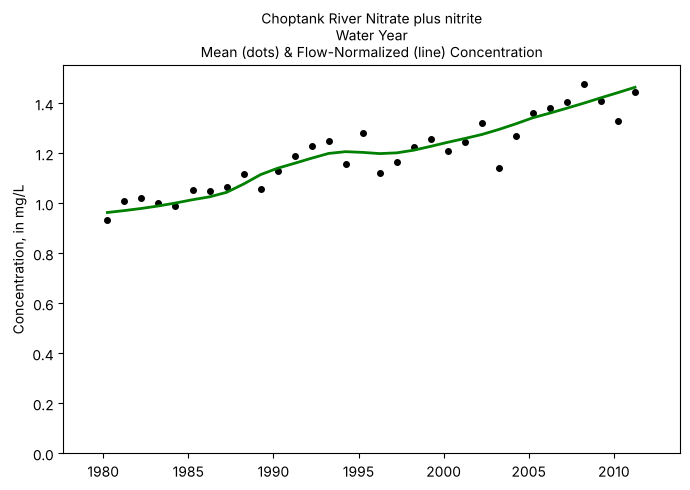

In [18]:
elist = model_estimation(elist, verbose=False)
fig, ax = plots.plot_conc_hist(elist)

This is the same history as in Tutorial 1. The rounding differences in
discharge are far too small to move it.

## 7. Keeping a copy of what you downloaded

USGS records change: values are revised, and results are added, approved or
corrected. To make an analysis repeatable, save the data you used, in the
plain format of Tutorial 2 so that they can be read back without an internet
connection, and note the date you downloaded them. Here the files go into a
temporary folder; for real work, use your project folder.

In [19]:
import datetime
import tempfile

SAVE_TO = tempfile.mkdtemp()      # for real work: your project folder
today = datetime.date.today()
tag = f"{SITE}_{PARAMETER}_downloaded_{today.isoformat()}"

daily_file = os.path.join(SAVE_TO, tag + "_daily.csv")
daily_out = pd.DataFrame({
    "date": daily["Date"].dt.strftime("%Y-%m-%d"),
    "discharge_cms": daily["Q"],
})
daily_out.to_csv(daily_file, index=False)

sample_file = os.path.join(SAVE_TO, tag + "_sample.csv")
sample_out = pd.DataFrame({
    "date": sample["Date"].dt.strftime("%Y-%m-%d"),
    "remark": np.where(sample["Uncen"] == 0, "<", ""),
    "value": sample["ConcHigh"],
})
sample_out.to_csv(sample_file, index=False)

info_file = os.path.join(SAVE_TO, tag + "_info.csv")
info.to_csv(info_file, index=False)

print(os.path.basename(daily_file))
print(os.path.basename(sample_file))
print(os.path.basename(info_file))

01491000_00631_downloaded_2026-10-27_daily.csv
01491000_00631_downloaded_2026-10-27_sample.csv
01491000_00631_downloaded_2026-10-27_info.csv


Two details matter when writing the files. The discharge in `Daily` is
already in cubic meters per second, so it must be read back with `q_unit=2`.
And a "less than" result is written as `<` with its reporting limit, which is
`ConcHigh`. (This simple version assumes there are no "greater than"
results, which WRTDS data rarely have.) Reading the files back gives the same
record:

In [20]:
daily_again = read_user_daily(daily_file, q_unit=2, verbose=False)
sample_again = read_user_sample(sample_file, verbose=False)
info_again = pd.read_csv(info_file, dtype={"monitoring_location_number": str,
                                           "paramNumber": str, "param_cd": str})

print("discharge the same:", np.allclose(daily_again["Q"], daily["Q"]))
print("samples the same:  ", np.allclose(sample_again["ConcHigh"], sample["ConcHigh"])
      and np.array_equal(sample_again["Uncen"].to_numpy(), sample["Uncen"].to_numpy()))

discharge the same: True
samples the same:   True


## 8. Your own site

To analyse another site, change `SITE`, `PARAMETER`, `START` and `END` in
section 1 and run the notebook again. Leave `START` and `END` empty (`""`) to
get the whole record. Read the messages from `read_waterdata_sample` each
time, and look at the descriptive columns before deciding what to keep.

**Rate limits.** Without a key, the USGS Water Data APIs allow a limited
number of requests per hour, which is plenty for a few sites. For many sites,
get a free API key at <https://api.waterdata.usgs.gov/signup> and put it in
the environment variable `API_USGS_PAT` before starting Python;
`dataretrieval` uses it automatically.

**The older readers.** PyEGRET also has `read_nwis_daily`, `read_nwis_sample`
and `read_nwis_info`, which use the legacy NWIS web services. USGS is retiring
those services, so use the `read_waterdata_` readers for new work.

**Sources.** Data: U.S. Geological Survey, Water Data for the Nation.
Software: `dataretrieval` (USGS); the readers translate EGRET 3.0.12's
`readNWISDaily`, `readNWISSample` and `readNWISInfo` (Hirsch, De Cicco and
Murphy).